In [ ]:
import numpy as np 
import pandas as pd  
import matplotlib.pyplot as plt  
import matplotlib.dates as mdates
import seaborn as sns

In [ ]:
df = pd.read_csv("SolarPrediction.csv")
df

In [ ]:
df.head()

In [ ]:
df['Datetime'] = pd.to_datetime(df['Data'] + ' ' + df['Time'])
df.drop(["Data","Time","UNIXTime"], axis = 1,inplace=True)

In [ ]:
df.head()

In [ ]:
df_day = df[df['Datetime'].dt.date == pd.to_datetime("2016-09-1").date()]
ax = sns.lineplot(data=df_day, x='Datetime', y='Radiation')
ax.xaxis.set_major_formatter(mdates.DateFormatter('%H:%M'))
ax.xaxis.set_major_locator(mdates.HourLocator(interval=1))
plt.xticks(rotation = 90)

In [ ]:
df['Datetime'] = pd.to_datetime(df['Datetime'])
df_filtered = df[(df['Datetime'] >= '2016-09-01') &(df['Datetime'] < '2017-01-01')].copy()
df_filtered['Radiation'] = pd.to_numeric(df_filtered['Radiation'], errors='coerce')
df_filtered = df_filtered.dropna(subset=['Datetime', 'Radiation'])
df_filtered['Time'] = (df_filtered['Datetime'].dt.hour * 60+ df_filtered['Datetime'].dt.minute)
df_filtered['Day'] = df_filtered['Datetime'].dt.date
days = sorted(df_filtered['Day'].unique())
for i in range(0, len(days), 7):
    selected_days = days[i:i + 7]
    week_df = df_filtered[df_filtered['Day'].isin(selected_days)]
    plt.figure(figsize=(12, 5))
    sns.lineplot(data=week_df,x='Time',y='Radiation',hue='Day',palette='tab10',errorbar=None)
    plt.xticks(range(0, 1440, 120),[f'{h:02d}:00' for h in range(0, 24,2)])
    plt.xlabel('Time of Day')
    plt.ylabel('Solar Radiation')
    plt.title(f'Solar Radiation: {selected_days[0]} to {selected_days[-1]}')
    plt.grid(alpha=0.25)
    plt.legend(title='Date', bbox_to_anchor=(1.02, 1), loc='upper left')
    plt.tight_layout()
    plt.savefig(f'Radiation plots\Solar Radiation vs Days,{selected_days[0]} to {selected_days[-1]}.png')

In [ ]:
month_order = ['September', 'October', 'November', 'December']
df_filtered['Month'] = df_filtered['Datetime'].dt.month_name()
fig, axes = plt.subplots(2, 2, figsize=(15, 9), sharex=True, sharey=True)
axes = axes.flatten()

for ax, month in zip(axes, month_order):
    month_data = df_filtered[df_filtered['Month'] == month]

    sns.lineplot(
        data=month_data,
        x='Time',
        y='Radiation',
        estimator='mean',
        errorbar=None,
        color='#E69F00',
        linewidth=2,
        ax=ax
    )

    ax.set_title(month, fontsize=14, fontweight='bold')
    ax.set_xlabel('Time of Day')
    ax.set_ylabel('Solar Radiation')
    ax.set_xticks(range(0, 1440, 120))
    ax.set_xticklabels(
        [f'{h:02d}:00' for h in range(0, 24, 2)],
        rotation=45
    )
    ax.grid(alpha=0.25)

fig.suptitle(
    'Monthly Average Daily Solar Radiation Profiles (2016)',
    fontsize=17,
    fontweight='bold'
)

plt.tight_layout()
plt.savefig("Radiation plots/Monthly Average Daily Solar Radiation Profiles (2016)")

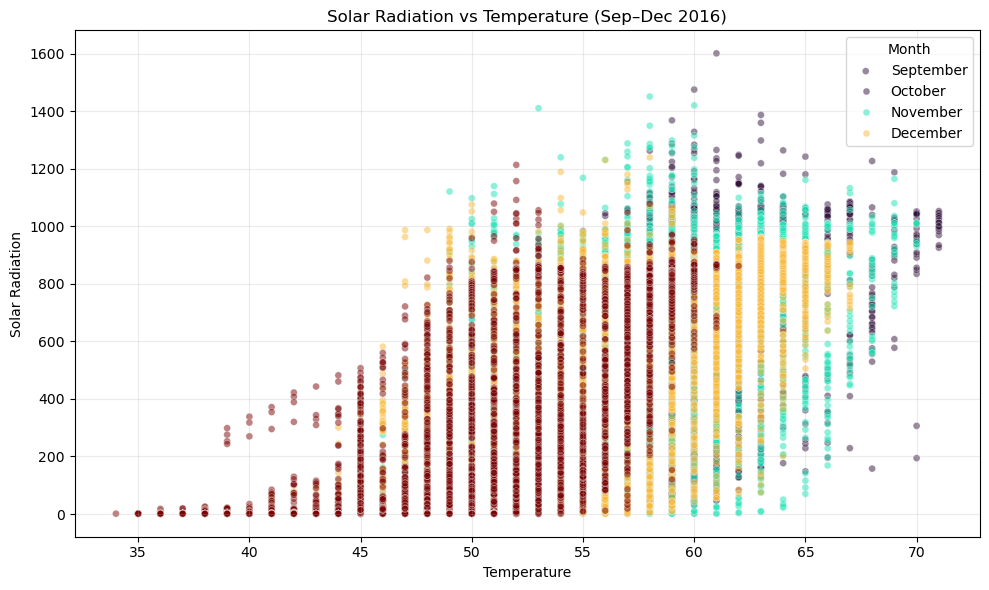

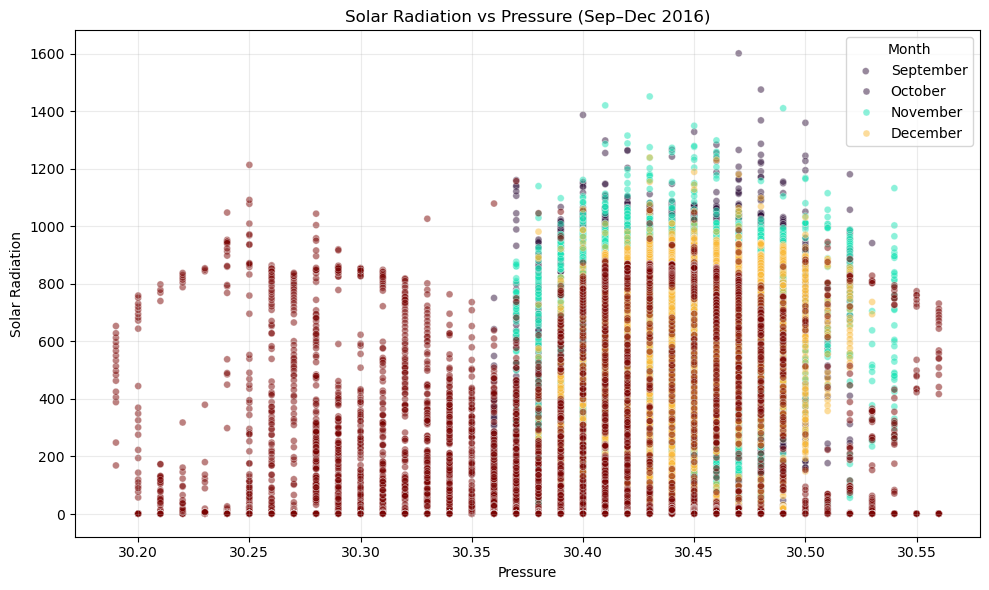

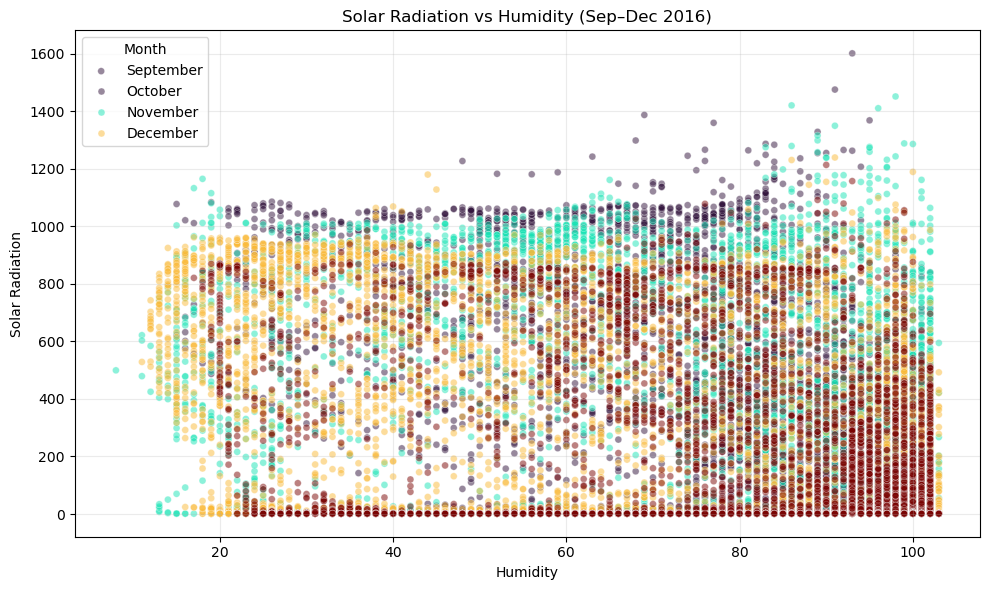

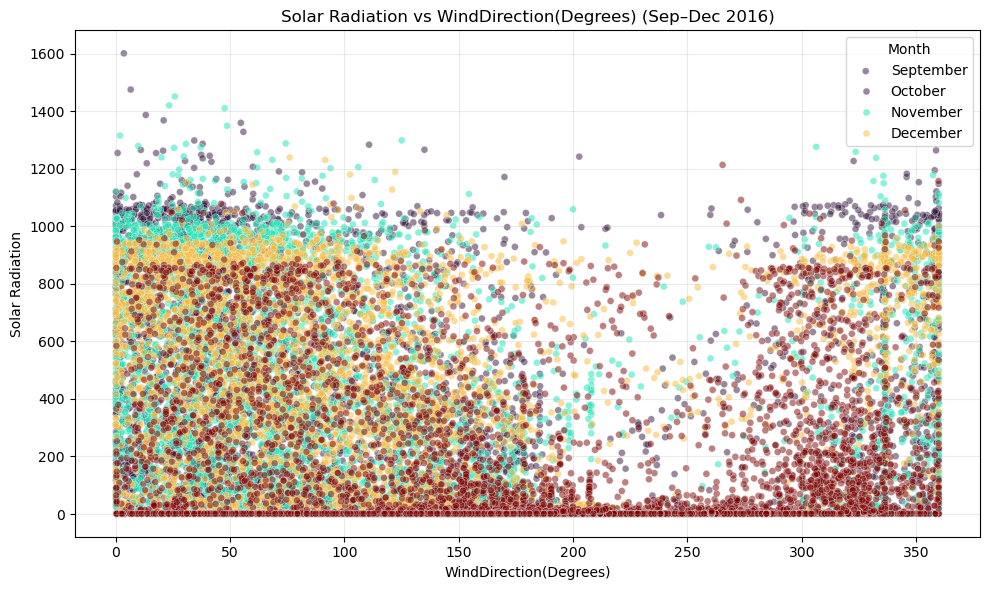

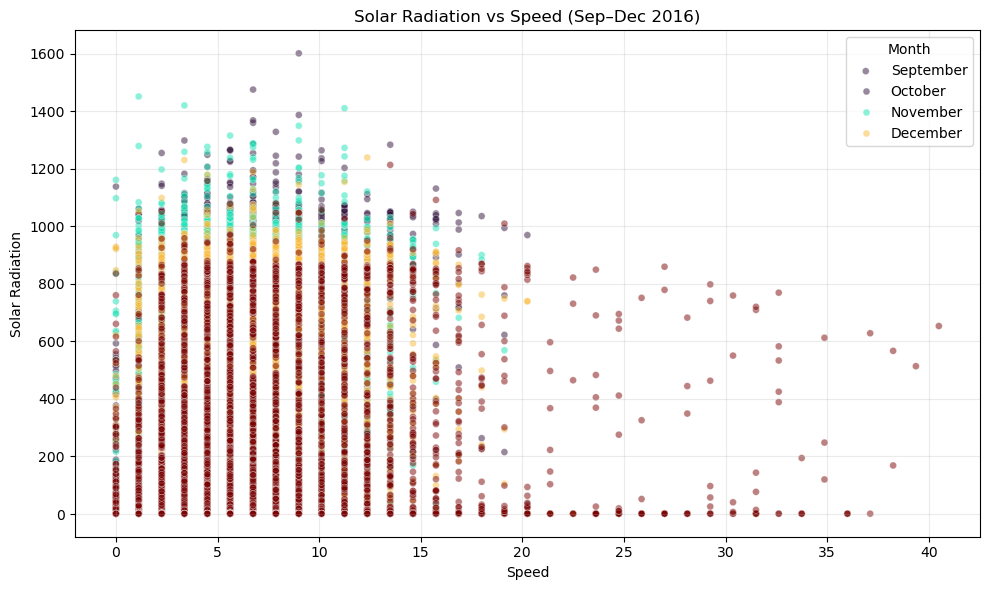

In [55]:
l1 = ["Temperature","Pressure","Humidity","WindDirection(Degrees)","Speed"]
for i in l1:
    plt.figure(figsize=(10, 6))

    sns.scatterplot(
        data=df_filtered,
        x=i,
        y='Radiation',
        hue=df_filtered['Datetime'].dt.month,
        palette='turbo',
        alpha=0.5,
        s=25
    )

    plt.xlabel(i)
    plt.ylabel('Solar Radiation')
    plt.title(f'Solar Radiation vs {i} (Sep–Dec 2016)')
    plt.grid(alpha=0.25)
    plt.legend(title='Month', labels=['September', 'October', 'November', 'December'])
    plt.tight_layout()
    plt.savefig(f"Radiation plots/Solar Radiation vs {i} (Sep–Dec 2016).png")

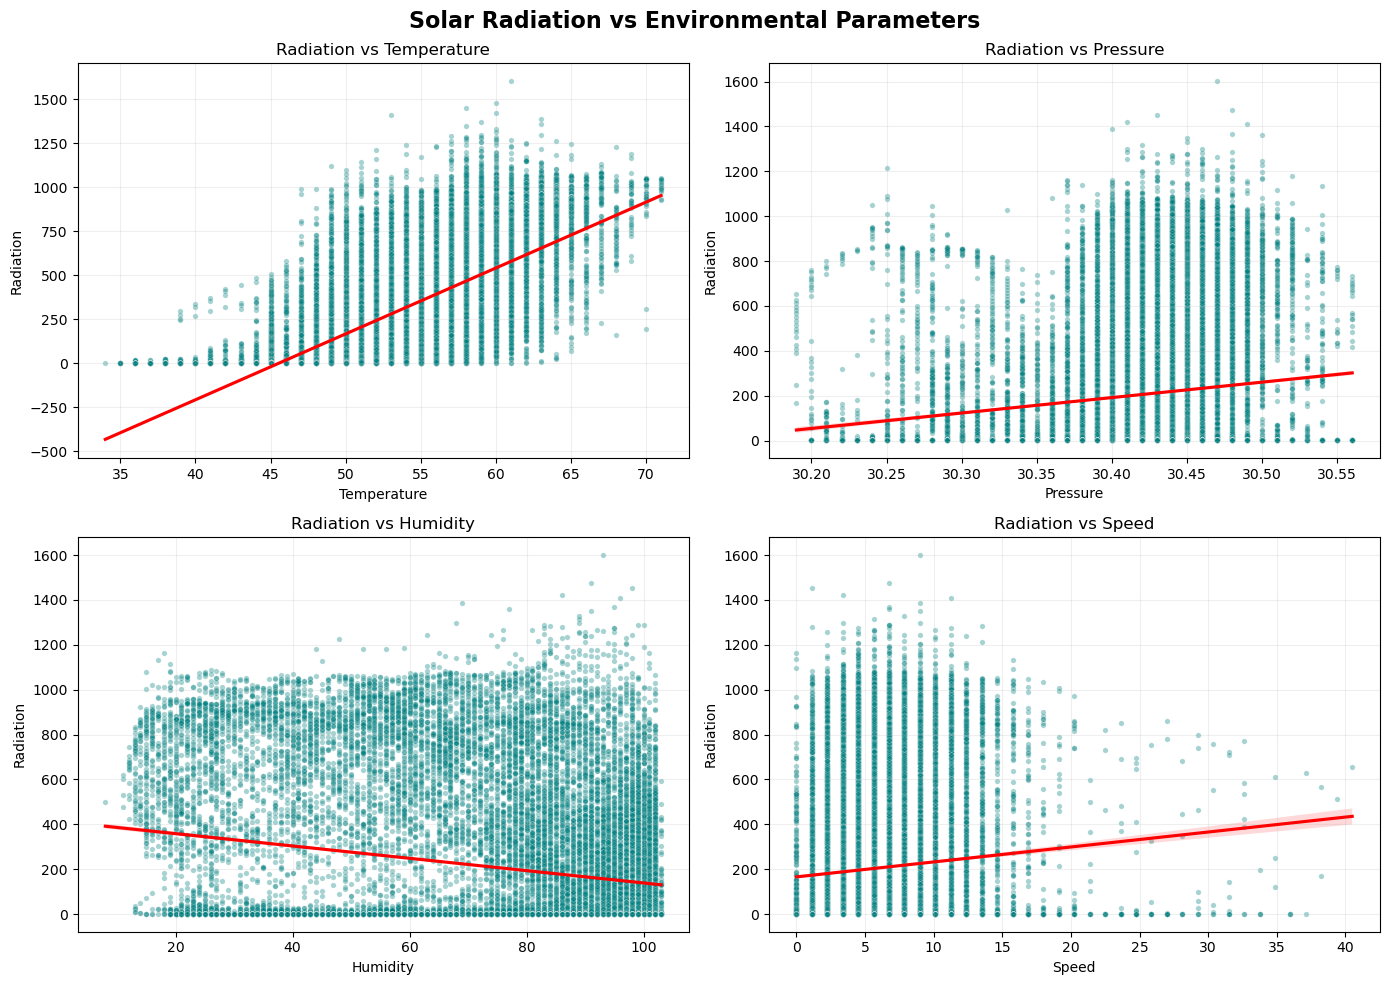

In [57]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

df['Datetime'] = pd.to_datetime(df['Datetime'])
df = df.sort_values('Datetime')

cols = ['Temperature', 'Pressure', 'Humidity', 'Speed']

fig, axes = plt.subplots(2, 2, figsize=(14, 10))

for ax, col in zip(axes.flatten(), cols):
    sns.scatterplot(
        data=df, x=col, y='Radiation',
        alpha=0.35, s=15, color='teal', ax=ax
    )
    sns.regplot(
        data=df, x=col, y='Radiation',
        scatter=False, color='red', ax=ax
    )
    ax.set_title(f'Radiation vs {col}')
    ax.grid(alpha=0.2)

plt.suptitle('Solar Radiation vs Environmental Parameters',
             fontsize=16, fontweight='bold')
plt.tight_layout()
plt.show()

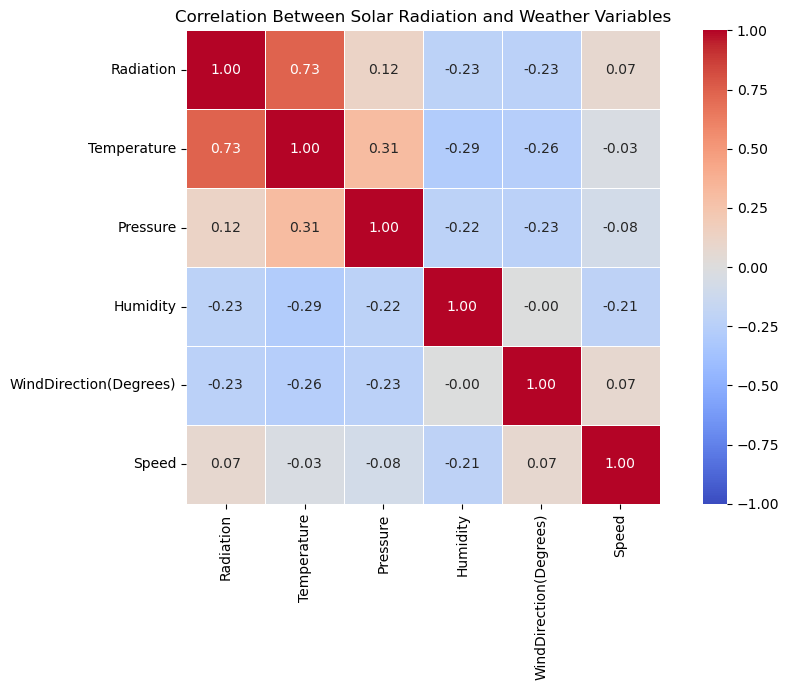

In [59]:
plt.figure(figsize=(10, 7))

corr = df[
    ['Radiation', 'Temperature', 'Pressure', 'Humidity',
     'WindDirection(Degrees)', 'Speed']
].corr(numeric_only=True)

sns.heatmap(
    corr, annot=True, cmap='coolwarm',
    vmin=-1, vmax=1, center=0, fmt='.2f',
    square=True, linewidths=0.5
)

plt.title('Correlation Between Solar Radiation and Weather Variables')
plt.tight_layout()
plt.savefig("Radiation plots/Correlation Between Solar Radiation and Weather Variables")
plt.show()

In [60]:
df['Date'] = df['Datetime'].dt.date

daily = df.groupby('Date').agg(
    Max_Radiation=('Radiation', 'max'),
    Avg_Radiation=('Radiation', 'mean')
)

print(daily.head())

            Max_Radiation  Avg_Radiation
Date                                    
2016-09-01        1073.71     298.451600
2016-09-02        1062.01     333.471219
2016-09-03        1088.09     123.974574
2016-09-04        1601.26     153.584321
2016-09-05        1264.07     306.065125


In [61]:
peak_idx = df['Radiation'].idxmax()
peak = df.loc[peak_idx]

print("Peak date and time:", peak['Datetime'])
print("Maximum radiation:", peak['Radiation'])
print("Temperature:", peak['Temperature'])
print("Humidity:", peak['Humidity'])
print("Pressure:", peak['Pressure'])
print("Wind speed:", peak['Speed'])
print("Wind direction:", peak['WindDirection(Degrees)'])
print("Sunrise:", peak['TimeSunRise'])
print("Sunset:", peak['TimeSunSet'])

Peak date and time: 2016-09-04 12:15:04
Maximum radiation: 1601.26
Temperature: 61
Humidity: 93
Pressure: 30.47
Wind speed: 9.0
Wind direction: 3.56
Sunrise: 06:08:00
Sunset: 18:35:00


In [62]:
df['ClockTime'] = df['Datetime'].dt.strftime('%H:%M:%S')

df['Minutes_After_Sunrise'] = (
    pd.to_timedelta(df['ClockTime'])
    - pd.to_timedelta(df['TimeSunRise'])
).dt.total_seconds() / 60

df['Minutes_Before_Sunset'] = (
    pd.to_timedelta(df['TimeSunSet'])
    - pd.to_timedelta(df['ClockTime'])
).dt.total_seconds() / 60

peak = df.loc[df['Radiation'].idxmax()]

print("Peak radiation time:", peak['ClockTime'])
print("Minutes after sunrise:", peak['Minutes_After_Sunrise'])
print("Minutes before sunset:", peak['Minutes_Before_Sunset'])

Peak radiation time: 12:15:04
Minutes after sunrise: 367.06666666666666
Minutes before sunset: 379.93333333333334


            Max_Radiation  Avg_Radiation
Date                                    
2016-09-19        1085.75     335.504400
2016-09-02        1062.01     333.471219
2016-09-22        1053.17     325.515880
2016-09-25        1075.29     319.921514
2016-09-28        1029.30     312.400390


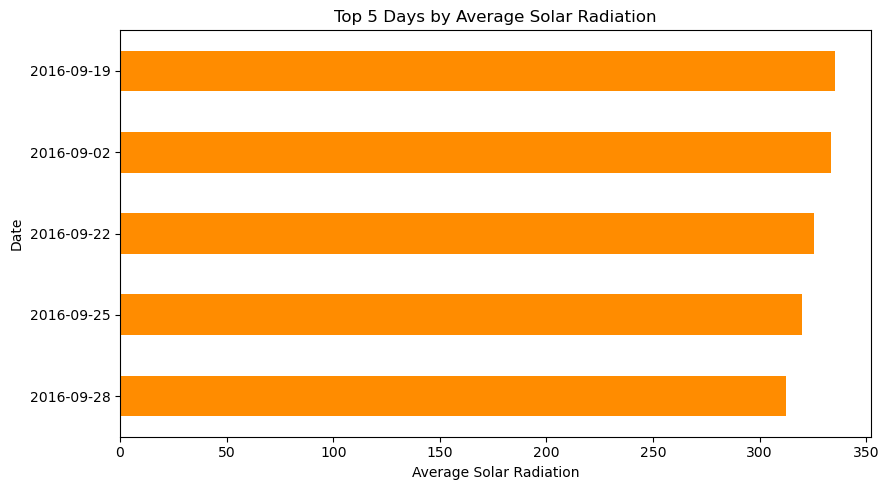

In [63]:
top5 = daily.nlargest(5, 'Avg_Radiation')

print(top5)

top5['Avg_Radiation'].sort_values().plot(
    kind='barh', figsize=(9, 5), color='darkorange'
)

plt.xlabel('Average Solar Radiation')
plt.ylabel('Date')
plt.title('Top 5 Days by Average Solar Radiation')
plt.tight_layout()
plt.show()